In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 

In [3]:

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns)

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape:
(2823, 25)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 

In [4]:

drop_columns = [
    'ADDRESSLINE1',
    'ADDRESSLINE2',
    'STATUS',
    'POSTALCODE',
    'CITY',
    'STATE',
    'TERRITORY',
    'CONTACTLASTNAME',
    'CONTACTFIRSTNAME',
    'PHONE',
    'CUSTOMERNAME',
    'ORDERDATE'
]

df.drop(
    columns=drop_columns,
    inplace=True,
    errors='ignore'
)

print("Unnecessary columns removed!")
print(df.head())


Unnecessary columns removed!
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  QTR_ID  \
0        10107               30      95.70                2  2871.00       1   
1        10121               34      81.35                5  2765.90       2   
2        10134               41      94.74                2  3884.34       3   
3        10145               45      83.26                6  3746.70       3   
4        10159               49     100.00               14  5205.27       4   

   MONTH_ID  YEAR_ID  PRODUCTLINE  MSRP PRODUCTCODE COUNTRY DEALSIZE  
0         2     2003  Motorcycles    95    S10_1678     USA    Small  
1         5     2003  Motorcycles    95    S10_1678  France    Small  
2         7     2003  Motorcycles    95    S10_1678  France   Medium  
3         8     2003  Motorcycles    95    S10_1678     USA   Medium  
4        10     2003  Motorcycles    95    S10_1678     USA   Medium  


In [5]:

print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numerical values with median
for col in df.select_dtypes(include=['number']).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
ORDERNUMBER        0
QUANTITYORDERED    0
PRICEEACH          0
ORDERLINENUMBER    0
SALES              0
QTR_ID             0
MONTH_ID           0
YEAR_ID            0
PRODUCTLINE        0
MSRP               0
PRODUCTCODE        0
COUNTRY            0
DEALSIZE           0
dtype: int64

Missing values after cleaning:
ORDERNUMBER        0
QUANTITYORDERED    0
PRICEEACH          0
ORDERLINENUMBER    0
SALES              0
QTR_ID             0
MONTH_ID           0
YEAR_ID            0
PRODUCTLINE        0
MSRP               0
PRODUCTCODE        0
COUNTRY            0
DEALSIZE           0
dtype: int64


In [6]:

# Create dummy variables
productline = pd.get_dummies(
    df['PRODUCTLINE'],
    prefix='ProductLine',
    dtype=int
)

dealsize = pd.get_dummies(
    df['DEALSIZE'],
    prefix='DealSize',
    dtype=int
)

# Combine dummy variables with dataset
df = pd.concat(
    [df, productline, dealsize],
    axis=1
)

# Remove original categorical columns
df.drop(
    ['PRODUCTLINE', 'DEALSIZE', 'COUNTRY'],
    axis=1,
    inplace=True,
    errors='ignore'
)

print("Categorical encoding completed!")
print(df.head())


Categorical encoding completed!
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  QTR_ID  \
0        10107               30      95.70                2  2871.00       1   
1        10121               34      81.35                5  2765.90       2   
2        10134               41      94.74                2  3884.34       3   
3        10145               45      83.26                6  3746.70       3   
4        10159               49     100.00               14  5205.27       4   

   MONTH_ID  YEAR_ID  MSRP PRODUCTCODE  ProductLine_Classic Cars  \
0         2     2003    95    S10_1678                         0   
1         5     2003    95    S10_1678                         0   
2         7     2003    95    S10_1678                         0   
3         8     2003    95    S10_1678                         0   
4        10     2003    95    S10_1678                         0   

   ProductLine_Motorcycles  ProductLine_Planes  ProductLine_Ships  \
0        

In [7]:

# Select numerical columns
numeric_df = df.select_dtypes(
    include=['number']
).copy()

# Remove identifier columns
numeric_df.drop(
    columns=[
        'ORDERNUMBER',
        'ORDERLINENUMBER',
        'CUSTOMERID'
    ],
    inplace=True,
    errors='ignore'
)

print("Selected Numerical Features:")
print(numeric_df.head())

print("\nFeature Shape:")
print(numeric_df.shape)


Selected Numerical Features:
   QUANTITYORDERED  PRICEEACH    SALES  QTR_ID  MONTH_ID  YEAR_ID  MSRP  \
0               30      95.70  2871.00       1         2     2003    95   
1               34      81.35  2765.90       2         5     2003    95   
2               41      94.74  3884.34       3         7     2003    95   
3               45      83.26  3746.70       3         8     2003    95   
4               49     100.00  5205.27       4        10     2003    95   

   ProductLine_Classic Cars  ProductLine_Motorcycles  ProductLine_Planes  \
0                         0                        1                   0   
1                         0                        1                   0   
2                         0                        1                   0   
3                         0                        1                   0   
4                         0                        1                   0   

   ProductLine_Ships  ProductLine_Trains  ProductLine_Trucks an

In [8]:

# Replace infinite values
numeric_df = numeric_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values
numeric_df = numeric_df.fillna(
    numeric_df.median()
)

# Standardize features
scaler = StandardScaler()

scaled_data = scaler.fit_transform(numeric_df)

print("Feature scaling completed!")
print("Scaled data shape:", scaled_data.shape)


Feature scaling completed!
Scaled data shape: (2823, 17)


In [9]:

wcss = []

for k in range(1, 10):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    wcss.append(kmeans.inertia_)

print("WCSS Values:")
print(wcss)


WCSS Values:
[47991.00000000003, 38566.69664517859, 34330.995366838855, 31697.89679033925, 29400.78809115888, 26840.438796511466, 24516.852011479834, 22700.259636232015, 20466.521927471855]


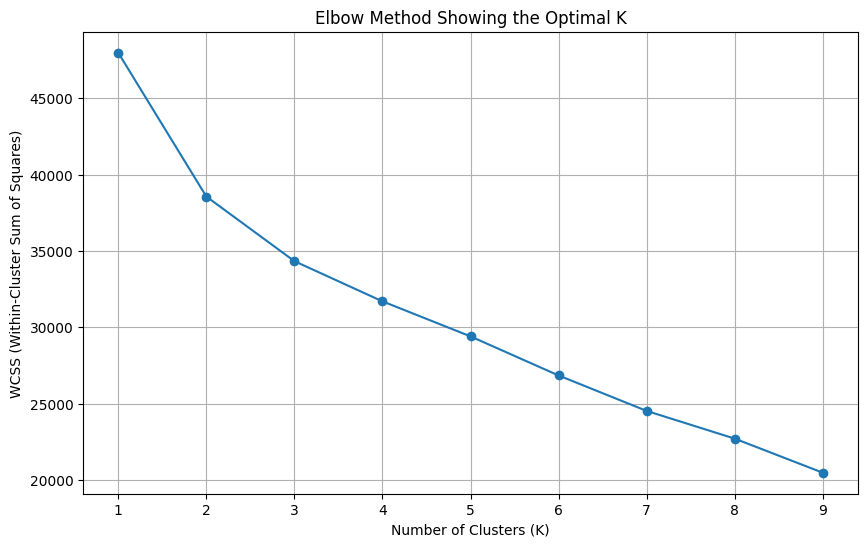

In [10]:

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 10),
    wcss,
    marker='o'
)

plt.title("Elbow Method Showing the Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(range(1, 10))
plt.grid(True)

plt.show()


In [11]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

predictions = kmeans.fit_predict(scaled_data)

print("K-Means Clustering Completed!")
print("Cluster Predictions:")
print(predictions)


K-Means Clustering Completed!
Cluster Predictions:
[0 0 1 ... 1 0 1]


In [12]:

cluster_counts = pd.Series(
    predictions
).value_counts().sort_index()

print("Number of records in each cluster:")
print(cluster_counts)


Number of records in each cluster:
0    1282
1    1384
2     157
Name: count, dtype: int64


In [13]:

pca = PCA(n_components=2)

reduced_data = pca.fit_transform(scaled_data)

reduced_df = pd.DataFrame(
    reduced_data,
    columns=['PCA1', 'PCA2']
)

reduced_df['Clusters'] = predictions

print("Reduced Data:")
print(reduced_df.head())


Reduced Data:
       PCA1      PCA2  Clusters
0 -1.074594 -1.326076         0
1 -1.301896 -0.332153         0
2  1.032430  0.511088         1
3  0.858569  0.640556         1
4  1.641598  1.479326         1


In [14]:

reduced_centers = pca.transform(
    kmeans.cluster_centers_
)

print("Reduced Cluster Centers:")
print(reduced_centers)


Reduced Cluster Centers:
[[-1.94359486  0.00685884]
 [ 1.4128883   0.03823371]
 [ 3.41561283 -0.3930477 ]]


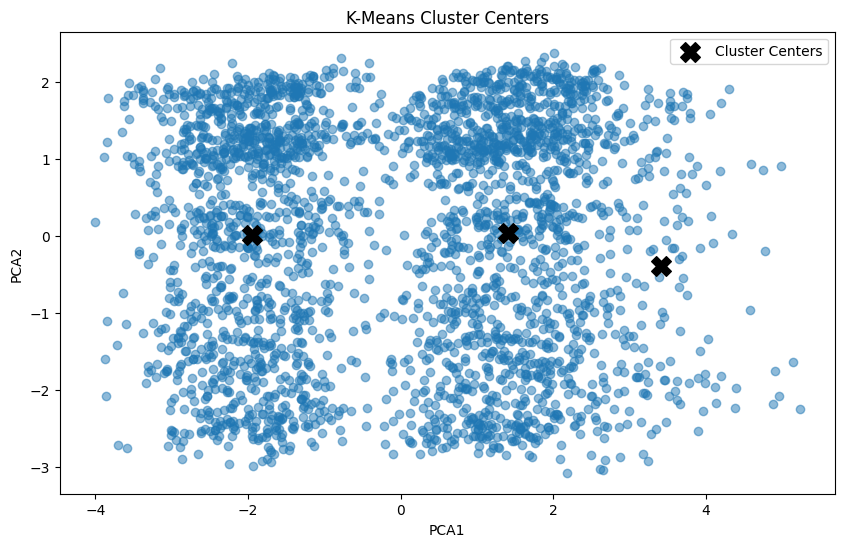

In [15]:

plt.figure(figsize=(10, 6))

plt.scatter(
    reduced_df['PCA1'],
    reduced_df['PCA2'],
    alpha=0.5
)

plt.scatter(
    reduced_centers[:, 0],
    reduced_centers[:, 1],
    color='black',
    marker='X',
    s=200,
    label='Cluster Centers'
)

plt.title("K-Means Cluster Centers")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()

plt.show()


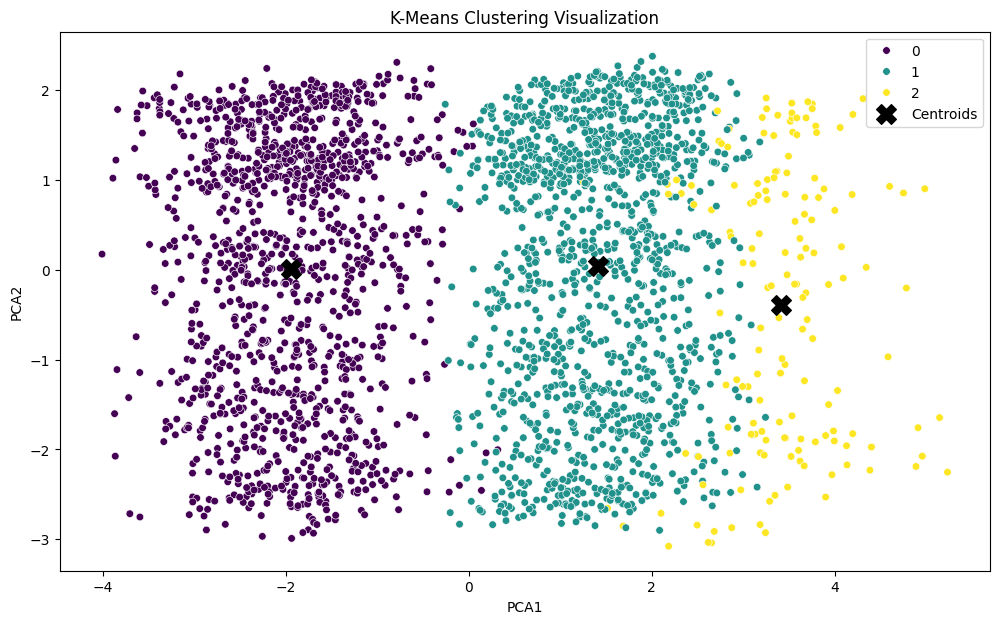

In [16]:

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=reduced_df,
    x='PCA1',
    y='PCA2',
    hue='Clusters',
    palette='viridis',
    s=30
)

plt.scatter(
    reduced_centers[:, 0],
    reduced_centers[:, 1],
    color='black',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("K-Means Clustering Visualization")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()

plt.show()
